In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import sklearn

print("Creative Intelligence AI")
print("Environment setup successful!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

Creative Intelligence AI
Environment setup successful!
NumPy: 2.5.5
Pandas: 3.1.1
OpenCV: 5.1.0


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/KAG_conversion_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (1143, 11)


,ad_id,xyz_campaign_id,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ad_id                1143 non-null   int64  
 1   xyz_campaign_id      1143 non-null   int64  
 2   fb_campaign_id       1143 non-null   int64  
 3   age                  1143 non-null   str    
 4   gender               1143 non-null   str    
 5   interest             1143 non-null   int64  
 6   Impressions          1143 non-null   int64  
 7   Clicks               1143 non-null   int64  
 8   Spent                1143 non-null   float64
 9   Total_Conversion     1143 non-null   int64  
 10  Approved_Conversion  1143 non-null   int64  
dtypes: float64(1), int64(8), str(2)
memory usage: 98.4 KB


In [4]:
df.isnull().sum()

ad_id                  0
xyz_campaign_id        0
fb_campaign_id         0
age                    0
gender                 0
interest               0
Impressions            0
Clicks                 0
Spent                  0
Total_Conversion       0
Approved_Conversion    0
dtype: int64

In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1143, 11)

Column Names:
['ad_id', 'xyz_campaign_id', 'fb_campaign_id', 'age', 'gender', 'interest', 'Impressions', 'Clicks', 'Spent', 'Total_Conversion', 'Approved_Conversion']

Statistical Summary:


,ad_id,xyz_campaign_id,fb_campaign_id,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
count,1.143000e+03,1143.000000,1143.000000,1143.000000,1.143000e+03,1143.000000,1143.000000,1143.000000,1143.000000
mean,9.872611e+05,1067.382327,133783.989501,32.766404,1.867321e+05,33.390201,51.360656,2.855643,0.944007
std,1.939928e+05,121.629393,20500.308622,26.952131,3.127622e+05,56.892438,86.908418,4.483593,1.737708
min,7.087460e+05,916.000000,103916.000000,2.000000,8.700000e+01,0.000000,0.000000,0.000000,0.000000
25%,7.776325e+05,936.000000,115716.000000,16.000000,6.503500e+03,1.000000,1.480000,1.000000,0.000000
50%,1.121185e+06,1178.000000,144549.000000,25.000000,5.150900e+04,8.000000,12.370000,1.000000,1.000000
75%,1.121804e+06,1178.000000,144657.500000,31.000000,2.217690e+05,37.500000,60.025000,3.000000,1.000000
max,1.314415e+06,1178.000000,179982.000000,114.000000,3.052003e+06,421.000000,639.949998,60.000000,21.000000



Data Types:
ad_id                    int64
xyz_campaign_id          int64
fb_campaign_id           int64
age                        str
gender                     str
interest                 int64
Impressions              int64
Clicks                   int64
Spent                  float64
Total_Conversion         int64
Approved_Conversion      int64
dtype: object


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1143, 11)

Column Names:
['ad_id', 'xyz_campaign_id', 'fb_campaign_id', 'age', 'gender', 'interest', 'Impressions', 'Clicks', 'Spent', 'Total_Conversion', 'Approved_Conversion']

Statistical Summary:


,ad_id,xyz_campaign_id,fb_campaign_id,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
count,1.143000e+03,1143.000000,1143.000000,1143.000000,1.143000e+03,1143.000000,1143.000000,1143.000000,1143.000000
mean,9.872611e+05,1067.382327,133783.989501,32.766404,1.867321e+05,33.390201,51.360656,2.855643,0.944007
std,1.939928e+05,121.629393,20500.308622,26.952131,3.127622e+05,56.892438,86.908418,4.483593,1.737708
min,7.087460e+05,916.000000,103916.000000,2.000000,8.700000e+01,0.000000,0.000000,0.000000,0.000000
25%,7.776325e+05,936.000000,115716.000000,16.000000,6.503500e+03,1.000000,1.480000,1.000000,0.000000
50%,1.121185e+06,1178.000000,144549.000000,25.000000,5.150900e+04,8.000000,12.370000,1.000000,1.000000
75%,1.121804e+06,1178.000000,144657.500000,31.000000,2.217690e+05,37.500000,60.025000,3.000000,1.000000
max,1.314415e+06,1178.000000,179982.000000,114.000000,3.052003e+06,421.000000,639.949998,60.000000,21.000000



Data Types:
ad_id                    int64
xyz_campaign_id          int64
fb_campaign_id           int64
age                        str
gender                     str
interest                 int64
Impressions              int64
Clicks                   int64
Spent                  float64
Total_Conversion         int64
Approved_Conversion      int64
dtype: object


In [7]:
print("Duplicate Rows:", df.duplicated().sum())
print("\nUnique Campaigns:", df["xyz_campaign_id"].nunique())
print("Unique Ad IDs:", df["ad_id"].nunique())
print("\nGender Distribution:")
print(df["gender"].value_counts())

print("\nAge Distribution:")
print(df["age"].value_counts())

Duplicate Rows: 0

Unique Campaigns: 3
Unique Ad IDs: 1143

Gender Distribution:
gender
M    592
F    551
Name: count, dtype: int64

Age Distribution:
age
30-34    426
45-49    259
35-39    248
40-44    210
Name: count, dtype: int64


In [8]:
import numpy as np

# Click Through Rate (%)
df["CTR"] = np.where(
    df["Impressions"] > 0,
    (df["Clicks"] / df["Impressions"]) * 100,
    0
)

# Conversion Rate (%)
df["Conversion_Rate"] = np.where(
    df["Clicks"] > 0,
    (df["Total_Conversion"] / df["Clicks"]) * 100,
    0
)

# Cost Per Click
df["CPC"] = np.where(
    df["Clicks"] > 0,
    df["Spent"] / df["Clicks"],
    0
)

# Cost Per Acquisition
df["CPA"] = np.where(
    df["Total_Conversion"] > 0,
    df["Spent"] / df["Total_Conversion"],
    0
)

display(df[[
    "Impressions", "Clicks", "Spent",
    "Total_Conversion", "CTR",
    "Conversion_Rate", "CPC", "CPA"
]].head(10))

,Impressions,Clicks,Spent,Total_Conversion,CTR,Conversion_Rate,CPC,CPA
0,7350,1,1.43,2,0.013605,200.000000,1.430000,0.715
1,17861,2,1.82,2,0.011198,100.000000,0.910000,0.910
2,693,0,0.00,1,0.000000,0.000000,0.000000,0.000
3,4259,1,1.25,1,0.023480,100.000000,1.250000,1.250
4,4133,1,1.29,1,0.024195,100.000000,1.290000,1.290
5,1915,0,0.00,1,0.000000,0.000000,0.000000,0.000
6,15615,3,4.77,1,0.019212,33.333333,1.590000,4.770
7,10951,1,1.27,1,0.009132,100.000000,1.270000,1.270
8,2355,1,1.50,1,0.042463,100.000000,1.500000,1.500
9,9502,3,3.16,1,0.031572,33.333333,1.053333,3.160


In [9]:
print("New Dataset Shape:", df.shape)
print("\nNew Features:")
print(df[["CTR", "Conversion_Rate", "CPC", "CPA"]].describe())

New Dataset Shape: (1143, 15)

New Features:
               CTR  Conversion_Rate          CPC          CPA
count  1143.000000      1143.000000  1143.000000  1143.000000
mean      0.016420        24.169930     1.227812    16.016721
std       0.011506        36.838128     0.614889    24.297504
min       0.000000         0.000000     0.000000     0.000000
25%       0.010022         2.857143     1.234500     1.380000
50%       0.015981         9.090909     1.450000     8.190000
75%       0.023364        25.000000     1.600000    21.229286
max       0.105932       400.000000     2.212000   332.989999


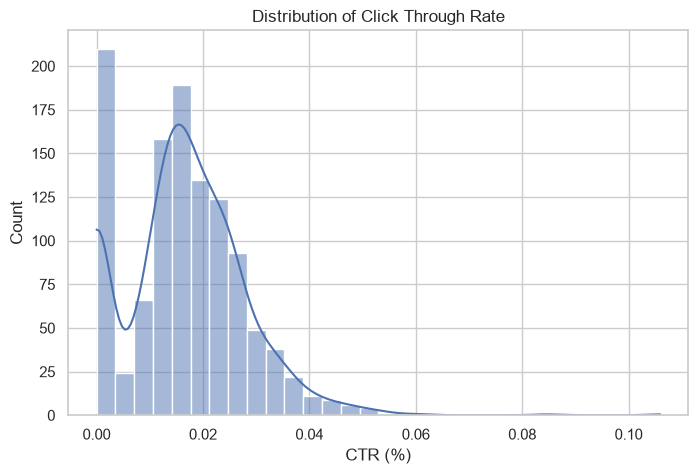

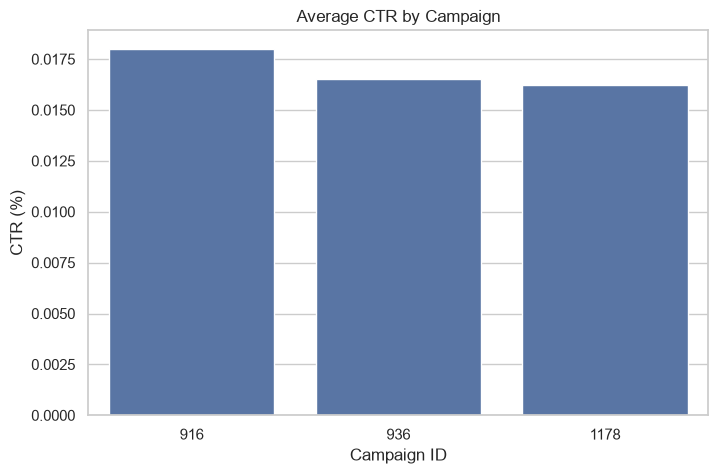

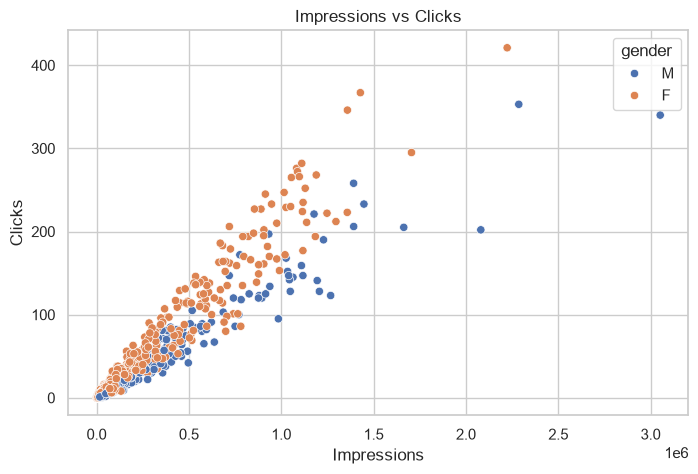

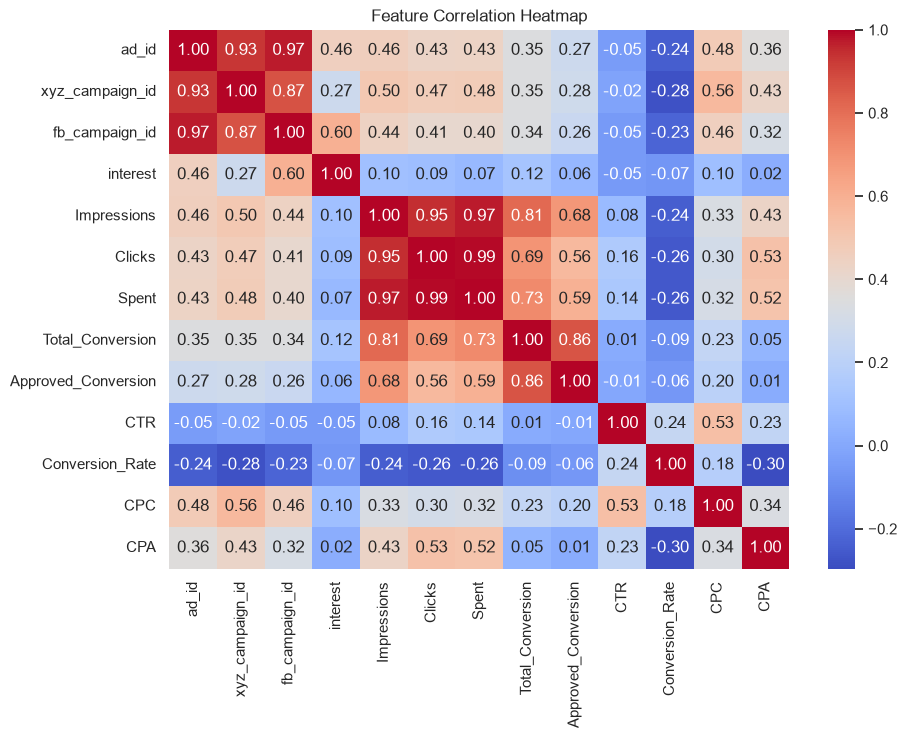

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. CTR Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["CTR"], bins=30, kde=True)
plt.title("Distribution of Click Through Rate")
plt.xlabel("CTR (%)")
plt.show()

# 2. Campaign-wise CTR
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="xyz_campaign_id", y="CTR", errorbar=None)
plt.title("Average CTR by Campaign")
plt.xlabel("Campaign ID")
plt.ylabel("CTR (%)")
plt.show()

# 3. Impressions vs Clicks
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Impressions", y="Clicks", hue="gender")
plt.title("Impressions vs Clicks")
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

In [11]:
# Define target
target = "Total_Conversion"

# Select input features
features = [
    "age",
    "gender",
    "interest",
    "xyz_campaign_id",
    "Impressions",
    "Spent"
]

X = df[features].copy()
y = df[target].copy()

# Encode categorical variables
X = pd.get_dummies(
    X,
    columns=["age", "gender"],
    drop_first=True,
    dtype=int
)

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Feature Shape: (1143, 8)
Target Shape: (1143,)


,interest,xyz_campaign_id,Impressions,Spent,age_35-39,age_40-44,age_45-49,gender_M
0,15,916,7350,1.43,0,0,0,1
1,16,916,17861,1.82,0,0,0,1
2,20,916,693,0.00,0,0,0,1
3,28,916,4259,1.25,0,0,0,1
4,28,916,4133,1.29,0,0,0,1


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 914
Testing samples: 229


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Input features and target
features = [
    "age", "gender", "interest",
    "xyz_campaign_id", "Impressions", "Spent"
]

X = df[features].copy()
y = df["Total_Conversion"].copy()

# Categorical columns
categorical_features = [
    "age", "gender", "interest", "xyz_campaign_id"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 914
Testing samples: 229


In [14]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline MAE:",
      round(mean_absolute_error(y_test, baseline_predictions), 3))

Baseline MAE: 2.464


In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=8
    ))
])

# Train model
model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

Random Forest Results
---------------------
MAE: 0.972
RMSE: 2.029
R2 Score: 0.782


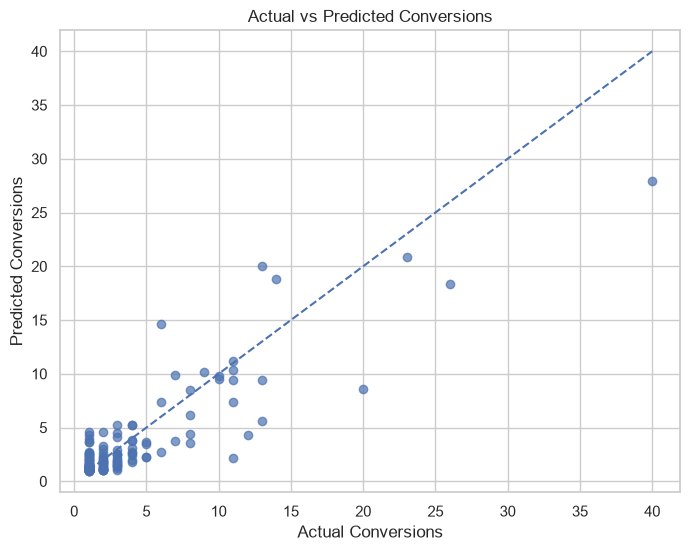

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Conversions")
plt.ylabel("Predicted Conversions")
plt.title("Actual vs Predicted Conversions")

plt.show()

In [18]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": np.round(predictions, 2)
})

display(results.head(15))

,Actual,Predicted
0,1,1.03
1,2,1.88
2,3,1.08
3,1,1.85
4,1,1.03
5,3,4.46
6,1,1.14
7,1,1.11
8,1,1.03
9,1,1.05


In [19]:
# Extract trained Random Forest
rf_model = model.named_steps["regressor"]

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create importance dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
49,remainder__Impressions,0.689424
50,remainder__Spent,0.125024
0,categorical__age_30-34,0.047808
32,categorical__interest_101,0.023672
35,categorical__interest_104,0.015847
43,categorical__interest_112,0.013135
42,categorical__interest_111,0.008941
9,categorical__interest_15,0.007906
4,categorical__gender_F,0.007554
5,categorical__gender_M,0.007366


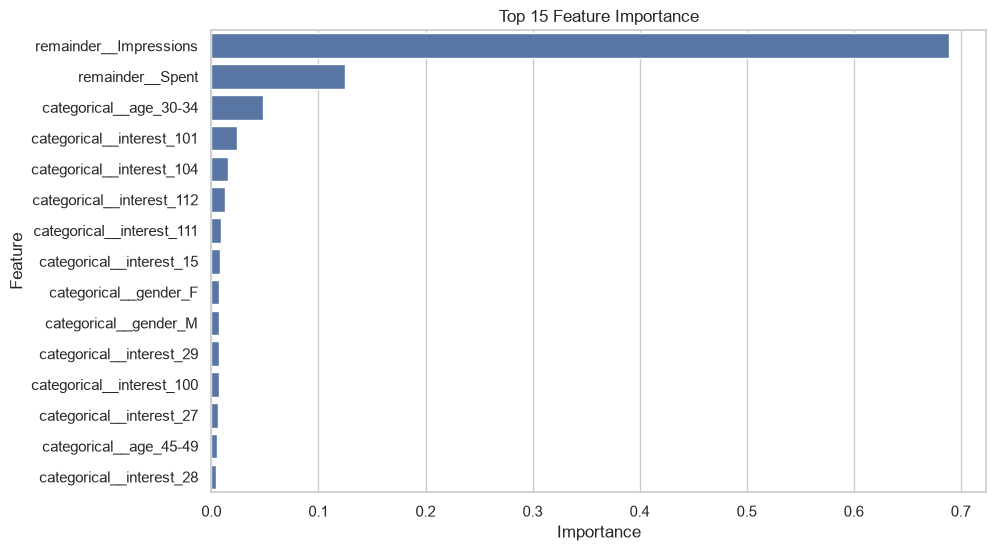

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance")
plt.show()

In [21]:
display(importance_df.head(15))

,Feature,Importance
49,remainder__Impressions,0.689424
50,remainder__Spent,0.125024
0,categorical__age_30-34,0.047808
32,categorical__interest_101,0.023672
35,categorical__interest_104,0.015847
43,categorical__interest_112,0.013135
42,categorical__interest_111,0.008941
9,categorical__interest_15,0.007906
4,categorical__gender_F,0.007554
5,categorical__gender_M,0.007366


In [26]:
# Convert sparse matrix into dense numeric array
X_test_numeric = X_test_transformed.toarray().astype(np.float64)

print("Data type:", X_test_numeric.dtype)
print("Shape:", X_test_numeric.shape)

Data type: float64
Shape: (229, 51)


In [27]:
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(
    X_test_numeric,
    check_additivity=False
)

print("SHAP analysis completed!")
print("SHAP values shape:", np.array(shap_values).shape)

SHAP analysis completed!
SHAP values shape: (229, 51)


In [29]:
print("SHAP shape:", shap_values.shape)
print("Data shape:", X_test_numeric.shape)
print("Feature names:", len(feature_names))

SHAP shape: (229, 51)
Data shape: (229, 51)
Feature names: 51


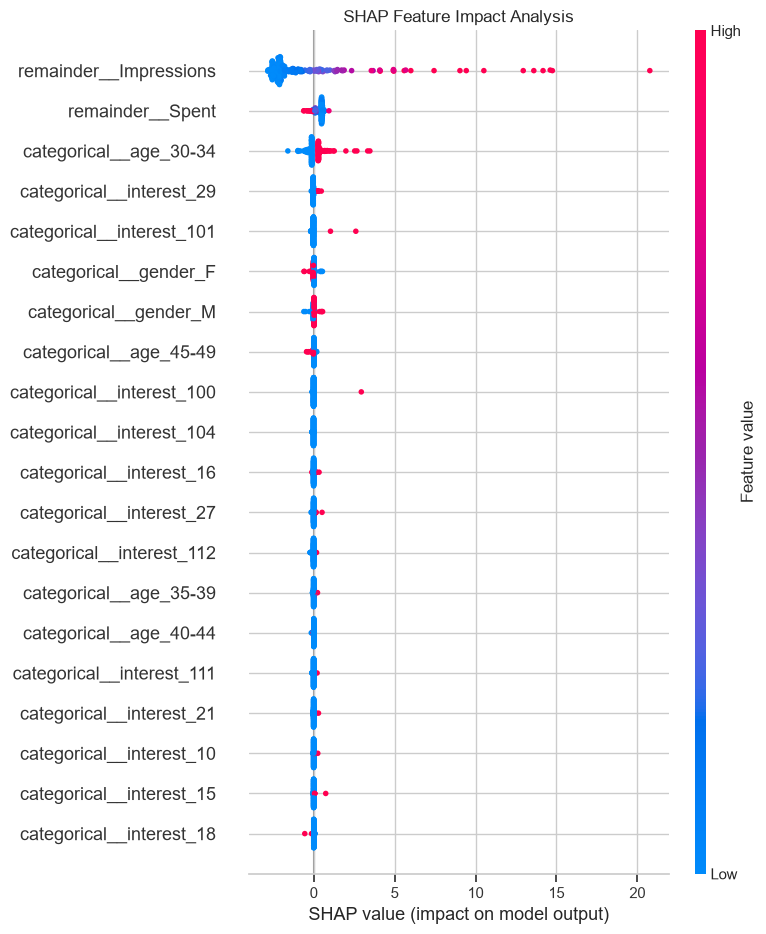

In [30]:
shap.summary_plot(
    shap_values,
    X_test_numeric,
    feature_names=list(feature_names),
    show=False
)

plt.title("SHAP Feature Impact Analysis")
plt.tight_layout()
plt.show()

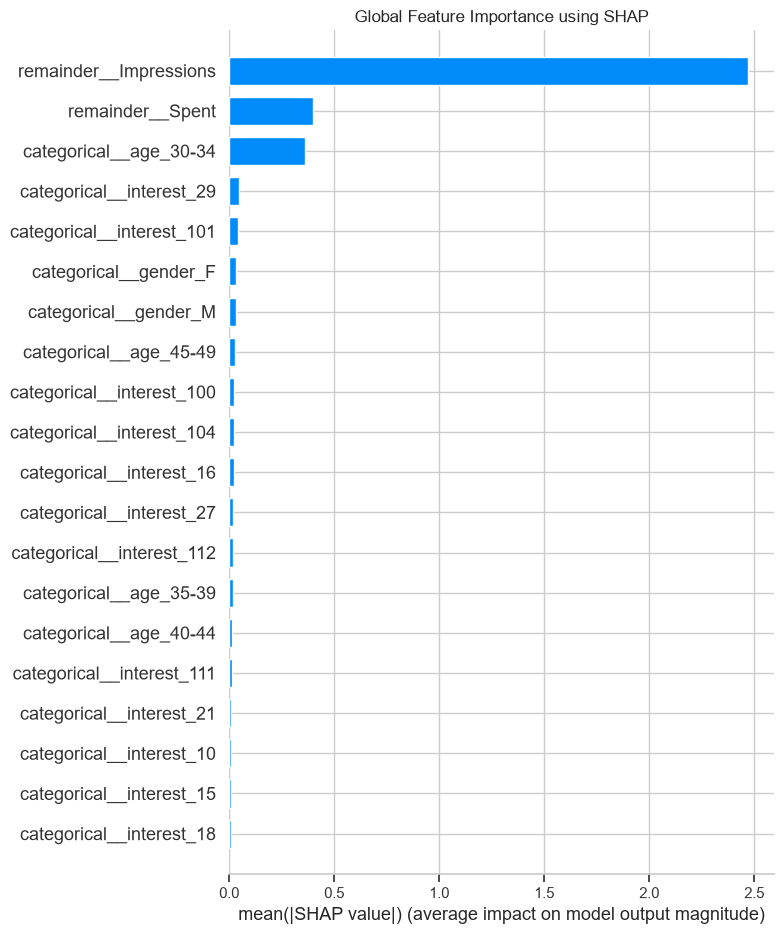

In [31]:
shap.summary_plot(
    shap_values,
    X_test_numeric,
    feature_names=list(feature_names),
    plot_type="bar",
    show=False
)

plt.title("Global Feature Importance using SHAP")
plt.tight_layout()
plt.show()